<a href="https://colab.research.google.com/github/MonnikLuianne/wildfire-risk-piaui/blob/main/wildfire_risk_piaui.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Daily Wildfire Risk Prediction in Piauí
   **Author:** Monnik Luianne Oliveira Nascimento Veloso Barbosa

## 1. Setup and Reproducibility
Libraries, versions and random seed used in this notebook.

In [1]:
import sys, random
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.18
pandas: 2.2.3
numpy: 2.4.6
scikit-learn: 1.6.1


## 2. Data Loading
Active fire detections (INPE – BDQueimadas, reference satellite AQUA_M-T), Piauí, 2015–2025.

In [2]:
BASE_URL = "https://raw.githubusercontent.com/MonnikLuianne/wildfire-risk-piaui/main/data/raw"
YEARS = range(2015, 2026)

frames = []
for year in YEARS:
    df_year = pd.read_csv(f"{BASE_URL}/focos_PI_{year}.csv")
    frames.append(df_year)
    print(year, len(df_year))

fires = pd.concat(frames, ignore_index=True)
print("Total:", fires.shape)
fires.head()

2015 13839
2016 8303
2017 7657
2018 9431
2019 10894
2020 9317
2021 12745
2022 10866
2023 12957
2024 10587
2025 11806
Total: (118402, 12)


,DataHora,Satelite,Pais,Estado,Municipio,Bioma,DiaSemChuva,Precipitacao,RiscoFogo,FRP,Latitude,Longitude
0,2015/01/01 17:05:00,AQUA_M-T,Brasil,PIAUÍ,CANAVIEIRA,Cerrado,0.0,0.3,0.0,28.3,-7.268,-43.717
1,2015/01/01 17:06:00,AQUA_M-T,Brasil,PIAUÍ,PIRACURUCA,Caatinga,1.0,0.0,1.0,80.5,-3.859,-41.591
2,2015/01/01 17:06:00,AQUA_M-T,Brasil,PIAUÍ,PIRACURUCA,Caatinga,1.0,0.0,1.0,101.9,-3.861,-41.595
3,2015/01/02 16:09:00,AQUA_M-T,Brasil,PIAUÍ,BOM JESUS,Cerrado,2.0,0.0,1.0,48.1,-9.149,-44.568
4,2015/01/02 16:09:00,AQUA_M-T,Brasil,PIAUÍ,MONTE ALEGRE DO PIAUÍ,Cerrado,2.0,0.0,1.0,27.8,-9.469,-44.831


### 2.1 Municipalities of Piauí
Coordinates (municipal seat) from the IBGE-based dataset by Kelvin S. do Prado (github.com/kelvins/municipios-brasileiros).

In [3]:
import unicodedata

def normalize(name):
    name = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode()
    return name.upper().strip()

MUN_URL = "https://raw.githubusercontent.com/kelvins/municipios-brasileiros/main/csv/municipios.csv"
municipalities = pd.read_csv(MUN_URL)
municipalities = municipalities[municipalities["codigo_uf"] == 22][["codigo_ibge", "nome", "latitude", "longitude"]]
municipalities["mun_key"] = municipalities["nome"].map(normalize)
print("Municipalities in Piauí:", len(municipalities))

fires["mun_key"] = fires["Municipio"].map(normalize)
unmatched = set(fires["mun_key"]) - set(municipalities["mun_key"])
print("Unmatched names:", unmatched)

Municipalities in Piauí: 224
Unmatched names: set()


### 2.2 Weather data (NASA POWER)
Daily weather for each municipality, obtained from the NASA POWER API (power.larc.nasa.gov), 2015–2025.
Variables: max temperature (T2M_MAX), mean temperature (T2M), relative humidity (RH2M), precipitation (PRECTOTCORR) and wind speed (WS2M).

In [4]:
import requests

POWER_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"
PARAMS = ["T2M_MAX", "T2M", "RH2M", "PRECTOTCORR", "WS2M"]

def get_weather(lat, lon, start="20150101", end="20251231"):
    query = {
        "parameters": ",".join(PARAMS),
        "community": "AG",
        "latitude": lat,
        "longitude": lon,
        "start": start,
        "end": end,
        "format": "JSON",
    }
    r = requests.get(POWER_URL, params=query, timeout=120)
    r.raise_for_status()
    data = r.json()["properties"]["parameter"]
    df = pd.DataFrame(data)
    df.index = pd.to_datetime(df.index, format="%Y%m%d")
    df.index.name = "date"
    return df.replace(-999, np.nan)

# Test with Teresina
the = municipalities[municipalities["mun_key"] == "TERESINA"].iloc[0]
test = get_weather(the["latitude"], the["longitude"])
print(test.shape)
print(test.isna().sum())
test.head()

(4018, 5)
T2M_MAX        0
T2M            0
RH2M           0
PRECTOTCORR    0
WS2M           0
dtype: int64


,T2M_MAX,T2M,RH2M,PRECTOTCORR,WS2M
date,,,,,
2015-01-01,31.87,27.59,66.72,0.93,1.08
2015-01-02,34.55,28.81,63.03,4.44,0.96
2015-01-03,26.37,24.36,85.66,8.81,0.92
2015-01-04,32.73,26.63,74.21,1.98,1.08
2015-01-05,32.43,27.06,71.00,4.57,1.15


In [5]:
import time
from tqdm.auto import tqdm

results = {}

for _, row in tqdm(municipalities.iterrows(), total=len(municipalities)):
    key = row["mun_key"]
    if key in results:
        continue  # already downloaded
    for attempt in range(3):
        try:
            w = get_weather(row["latitude"], row["longitude"])
            w["mun_key"] = key
            results[key] = w
            break
        except Exception as e:
            print(key, "- attempt", attempt + 1, "failed:", e)
            time.sleep(10)
    time.sleep(1)  # be gentle with the API

weather = pd.concat(results.values()).reset_index()
print(weather.shape, "| municipalities:", weather["mun_key"].nunique())
print(weather.isna().sum())

weather.to_csv("weather_PI_2015_2025.csv.gz", index=False, compression="gzip")

  0%|          | 0/224 [00:00<?, ?it/s]

(900032, 7) | municipalities: 224
date           0
T2M_MAX        0
T2M            0
RH2M           0
PRECTOTCORR    0
WS2M           0
mun_key        0
dtype: int64


## 3. Dataset Construction
Each row is a (municipality, day) pair. Target `fire` = 1 if at least one active fire was detected
by the reference satellite in that municipality on that day, 0 otherwise.
Note: 0 means "no detection", not certainty of absence (cloud cover, small fires and single daily overpass).

In [6]:
WEATHER_URL = "https://raw.githubusercontent.com/MonnikLuianne/wildfire-risk-piaui/main/data/processed/weather_PI_2015_2025.csv.gz"
weather = pd.read_csv(WEATHER_URL, parse_dates=["date"])
print("Weather loaded from GitHub:", weather.shape)

# One label per (municipality, day)
fires["date"] = pd.to_datetime(fires["DataHora"]).dt.normalize()
fire_days = fires[["mun_key", "date"]].drop_duplicates()
fire_days["fire"] = 1

data = weather.merge(fire_days, on=["mun_key", "date"], how="left")
data["fire"] = data["fire"].fillna(0).astype(int)

print("Dataset:", data.shape)
print("Fire days matched:", data["fire"].sum(), "of", len(fire_days))
print("Overall fire rate:", round(data["fire"].mean(), 4))
data.groupby(data["date"].dt.year)["fire"].agg(["sum", "mean"])

Weather loaded from GitHub: (900032, 7)
Dataset: (900032, 8)
Fire days matched: 38879 of 38879
Overall fire rate: 0.0432


,sum,mean
date,,
2015,3781,0.046245
2016,2962,0.036129
2017,2735,0.033452
2018,3063,0.037463
2019,3651,0.044655
2020,3111,0.037946
2021,3677,0.044973
2022,3572,0.043689
2023,4177,0.051089


## 4. Exploratory Data Analysis

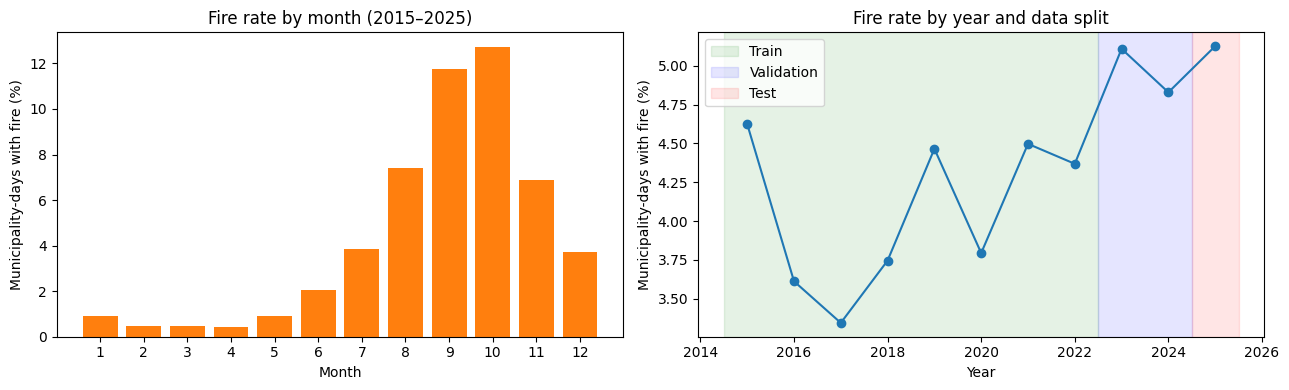

In [7]:
#Célula de código (gráfico 1: quando o fogo acontece):

import matplotlib.pyplot as plt

data["year"] = data["date"].dt.year
data["month"] = data["date"].dt.month

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

monthly = data.groupby("month")["fire"].mean() * 100
axes[0].bar(monthly.index, monthly.values, color="tab:orange")
axes[0].set_title("Fire rate by month (2015–2025)")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Municipality-days with fire (%)")
axes[0].set_xticks(range(1, 13))

yearly = data.groupby("year")["fire"].mean() * 100
axes[1].plot(yearly.index, yearly.values, marker="o")
axes[1].axvspan(2014.5, 2022.5, alpha=0.1, color="green", label="Train")
axes[1].axvspan(2022.5, 2024.5, alpha=0.1, color="blue", label="Validation")
axes[1].axvspan(2024.5, 2025.5, alpha=0.1, color="red", label="Test")
axes[1].set_title("Fire rate by year and data split")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Municipality-days with fire (%)")
axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretation.** Fire activity is strongly seasonal: from January to May the fire rate stays below 1%
(rainy season), rises from June onward and peaks in September–October (~12–13% of municipality-days),
dropping again as the rains return in November–December. This indicates that seasonality must be
represented in the model (e.g., month) and that class imbalance varies throughout the year.
Across years, the rate fluctuates between ~3.3% (2017) and ~5.1% (2023, 2025) without a clear trend
in the training period, but the validation and test years (2023–2025) are among the highest.
The test set is therefore slightly harder than the training conditions. The causes of this increase
(e.g., drier years) cannot be established from these data alone.

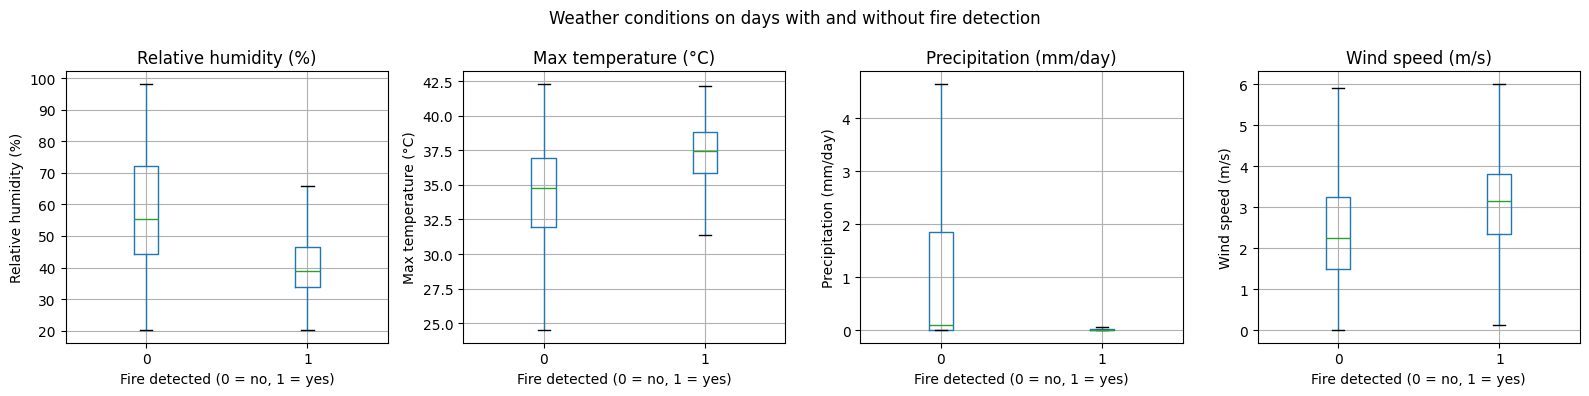

In [8]:
#Célula de código (gráfico 2: clima nos dias com e sem fogo):

variables = {
    "RH2M": "Relative humidity (%)",
    "T2M_MAX": "Max temperature (°C)",
    "PRECTOTCORR": "Precipitation (mm/day)",
    "WS2M": "Wind speed (m/s)",
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (col, label) in zip(axes, variables.items()):
    data.boxplot(column=col, by="fire", ax=ax, showfliers=False)
    ax.set_title(label)
    ax.set_xlabel("Fire detected (0 = no, 1 = yes)")
    ax.set_ylabel(label)

plt.suptitle("Weather conditions on days with and without fire detection")
plt.tight_layout()
plt.show()

**Interpretation.** Days with fire detection are drier (median relative humidity ≈40% vs ≈55%),
hotter (median max temperature ≈37.5 °C vs ≈35 °C) and windier (≈3.1 vs ≈2.3 m/s), and almost never
have rainfall. However, the distributions overlap, so no single variable separates the two classes,
which motivates a multivariate model. Same-day precipitation is weakly informative, since most
no-fire days also have zero rain; accumulated rainfall and consecutive dry days are likely better
indicators of fuel dryness and will be engineered in the next step. Part of these differences reflects
seasonality (fires occur in the dry season), so these are associations, not causal effects.
Outliers are hidden (showfliers=False) for readability.

## 5. Feature Engineering
To predict fire on day D, all features use only information available up to day D−1
(every feature is shifted by one day), preventing temporal leakage. Rolling features are computed
separately for each municipality.

| Feature | Description |
|---|---|
| `*_lag1` | Weather on the previous day |
| `rain_7d`, `rain_30d` | Accumulated precipitation over the previous 7 / 30 days (mm) |
| `dry_days` | Consecutive days with precipitation < 1 mm up to D−1 |
| `rh_mean_7d`, `tmax_mean_7d` | Mean relative humidity / max temperature over the previous 7 days |
| `fire_lag1`, `fire_7d` | Fire detected on D−1 / number of fire days in the previous 7 days |
| `month_sin`, `month_cos` | Cyclical encoding of the month |
| `latitude`, `longitude` | Municipal seat coordinates |

In [9]:
data = data.sort_values(["mun_key", "date"]).reset_index(drop=True)
g = data.groupby("mun_key")

# Previous-day weather
weather_cols = ["T2M_MAX", "T2M", "RH2M", "PRECTOTCORR", "WS2M"]
for col in weather_cols:
    data[f"{col}_lag1"] = g[col].shift(1)

# Accumulated / averaged weather (up to D-1)
data["rain_7d"] = g["PRECTOTCORR"].transform(lambda s: s.shift(1).rolling(7).sum())
data["rain_30d"] = g["PRECTOTCORR"].transform(lambda s: s.shift(1).rolling(30).sum())
data["rh_mean_7d"] = g["RH2M"].transform(lambda s: s.shift(1).rolling(7).mean())
data["tmax_mean_7d"] = g["T2M_MAX"].transform(lambda s: s.shift(1).rolling(7).mean())

# Consecutive dry days (precipitation < 1 mm), up to D-1
def consecutive_dry_days(s, threshold=1.0):
    dry = s < threshold
    return dry.groupby((~dry).cumsum()).cumsum()

data["dry_days"] = g["PRECTOTCORR"].transform(lambda s: consecutive_dry_days(s).shift(1))

# Fire history (up to D-1)
data["fire_lag1"] = g["fire"].shift(1)
data["fire_7d"] = g["fire"].transform(lambda s: s.shift(1).rolling(7).sum())

# Seasonality (cyclical month)
data["month_sin"] = np.sin(2 * np.pi * data["month"] / 12)
data["month_cos"] = np.cos(2 * np.pi * data["month"] / 12)

# Location
data = data.merge(municipalities[["mun_key", "latitude", "longitude"]], on="mun_key", how="left")

FEATURES = [f"{c}_lag1" for c in weather_cols] + [
    "rain_7d", "rain_30d", "rh_mean_7d", "tmax_mean_7d", "dry_days",
    "fire_lag1", "fire_7d", "month_sin", "month_cos", "latitude", "longitude",
]

before = len(data)
data = data.dropna(subset=FEATURES).reset_index(drop=True)
print("Rows dropped (start of the series):", before - len(data))
print("Final dataset:", data.shape)
data[FEATURES].describe().T.round(2)

Rows dropped (start of the series): 6720
Final dataset: (893312, 26)


,count,mean,std,min,25%,50%,75%,max
T2M_MAX_lag1,893312.0,34.55,3.30,23.24,32.07,34.89,37.06,42.31
T2M_lag1,893312.0,28.38,2.31,21.21,26.60,28.26,30.05,35.45
RH2M_lag1,893312.0,57.45,17.06,20.12,43.35,54.61,71.53,98.22
PRECTOTCORR_lag1,893312.0,2.09,4.91,0.00,0.00,0.08,1.71,122.08
WS2M_lag1,893312.0,2.41,1.25,0.00,1.51,2.30,3.30,7.06
rain_7d,893312.0,14.62,22.57,0.00,0.19,3.80,20.61,333.85
rain_30d,893312.0,62.53,75.53,0.00,3.78,33.67,97.68,646.09
rh_mean_7d,893312.0,57.44,16.28,25.02,44.02,54.80,70.81,95.09
tmax_mean_7d,893312.0,34.55,3.00,26.36,32.17,34.81,36.83,41.60
dry_days,893312.0,19.10,32.15,0.00,0.00,4.00,22.00,206.00


## 6. Experimental Protocol
Chronological split by whole years, preserving seasonality and preventing future information from
leaking into training:
- **Train:** 2015–2022 (model fitting)
- **Validation:** 2023–2024 (hyperparameter and decision-threshold selection)
- **Test:** 2025 (final evaluation, used only once)

In [10]:
train = data[data["year"] <= 2022]
val = data[data["year"].between(2023, 2024)]
test = data[data["year"] == 2025]

X_train, y_train = train[FEATURES], train["fire"]
X_val, y_val = val[FEATURES], val["fire"]
X_test, y_test = test[FEATURES], test["fire"]

total = len(data)
for name, part in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name:<10} {len(part):>8,} rows ({len(part)/total:.1%}) | "
          f"{part['year'].min()}–{part['year'].max()} | fire rate {part['fire'].mean():.2%}")

Train       647,808 rows (72.5%) | 2015–2022 | fire rate 4.09%
Validation  163,744 rows (18.3%) | 2023–2024 | fire rate 4.97%
Test         81,760 rows (9.2%) | 2025–2025 | fire rate 5.13%


## 7. Baselines
Three reference models, evaluated on the validation set (2023–2024):
1. **Persistence:** predicts fire on day D if fire was detected on D−1.
2. **Climatology:** fire probability = historical fire rate of the municipality in that month (computed on training data only).
3. **Logistic Regression:** linear model on all features (standardized; balanced class weights).

Because classes are highly imbalanced (≈5% positives), accuracy is not informative. The main metric is
**PR-AUC** (average precision; a random classifier scores ≈ the positive rate). Precision, recall and F1
are reported at the decision threshold that maximizes F1 on the validation set.

In [11]:
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def best_threshold(y_true, scores):
    p, r, t = precision_recall_curve(y_true, scores)
    f1 = 2 * p * r / (p + r + 1e-12)
    return t[np.argmax(f1[:-1])]

def evaluate(name, y_true, scores, threshold):
    pred = (scores >= threshold).astype(int)
    return {
        "model": name,
        "PR-AUC": average_precision_score(y_true, scores),
        "ROC-AUC": roc_auc_score(y_true, scores),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "threshold": threshold,
    }

results = []

# Baseline 1: persistence
s_pers_val = val["fire_lag1"].values
results.append(evaluate("Persistence", y_val, s_pers_val, 0.5))

# Baseline 2: climatology (training data only)
clim = train.groupby(["mun_key", "month"])["fire"].mean().rename("clim")
s_clim_val = val.join(clim, on=["mun_key", "month"])["clim"].fillna(train["fire"].mean()).values
results.append(evaluate("Climatology", y_val, s_clim_val, best_threshold(y_val, s_clim_val)))

# Baseline 3: logistic regression
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
logreg.fit(X_train, y_train)
s_lr_val = logreg.predict_proba(X_val)[:, 1]
results.append(evaluate("Logistic Regression", y_val, s_lr_val, best_threshold(y_val, s_lr_val)))

pd.DataFrame(results).round(3)

,model,PR-AUC,ROC-AUC,precision,recall,F1,threshold
0,Persistence,0.092,0.595,0.231,0.231,0.231,0.500
1,Climatology,0.308,0.868,0.319,0.448,0.373,0.171
2,Logistic Regression,0.318,0.861,0.342,0.415,0.375,0.832


**Interpretation.** Persistence is weak (PR-AUC 0.092): only ≈23% of fire days were preceded by a fire
day in the same municipality, i.e., fire detections rarely persist at the municipal level.
Climatology is a strong baseline (PR-AUC 0.308, ROC-AUC 0.868): knowing *where* and *when* already
explains a large share of fire occurrence, consistent with the strong seasonality observed in the EDA.
Logistic regression adds little over climatology (PR-AUC 0.318), possibly because a linear model cannot
capture interactions between dryness, heat and wind, and because many fires are human-ignited, so weather
only sets favorable conditions (a hypothesis, not tested here). Climatology is therefore the reference to beat.
Note: with balanced class weights the predicted probabilities are not calibrated, so the decision
threshold (0.832) is selected on the validation set.

## 8. Main Model: Random Forest
A Random Forest averages many decision trees, each trained on a bootstrap sample of the data and
considering a random subset of features at each split. Trees naturally capture non-linear interactions
(e.g., dry *and* hot *and* windy), and averaging reduces variance (overfitting) compared with a single tree.

Hyperparameters:
- `n_estimators=200`: number of trees
- `min_samples_leaf=50`: each leaf must contain at least 50 samples (limits overfitting)
- `max_features="sqrt"`: number of features considered at each split
- `max_samples=0.3`: each tree is trained on 30% of the training rows (speed and diversity)
- `class_weight="balanced_subsample"`: compensates class imbalance within each bootstrap sample

In [12]:
from sklearn.ensemble import RandomForestClassifier
import time

rf = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=50,
    max_features="sqrt",
    max_samples=0.3,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=SEED,
)

start = time.time()
rf.fit(X_train, y_train)
print(f"Training time: {time.time() - start:.0f} s")

s_rf_val = rf.predict_proba(X_val)[:, 1]
results = [r for r in results if r["model"] != "Random Forest"]  # avoid duplicates if re-run
results.append(evaluate("Random Forest", y_val, s_rf_val, best_threshold(y_val, s_rf_val)))
pd.DataFrame(results).round(3)

Training time: 99 s


,model,PR-AUC,ROC-AUC,precision,recall,F1,threshold
0,Persistence,0.092,0.595,0.231,0.231,0.231,0.500
1,Climatology,0.308,0.868,0.319,0.448,0.373,0.171
2,Logistic Regression,0.318,0.861,0.342,0.415,0.375,0.832
3,Random Forest,0.339,0.877,0.365,0.406,0.385,0.792


**Interpretation.** The Random Forest outperforms all baselines on the validation set
(PR-AUC 0.339 vs 0.308 for climatology and 0.318 for logistic regression), a ≈10% relative gain over
climatology. The larger gain compared with the linear model supports the hypothesis that non-linear
interactions between dryness, heat and wind carry predictive information. At the selected threshold,
it detects ≈41% of fire days with ≈37% precision (≈7× the precision of random alerts).
ROC-AUC differs little among models, as expected under strong class imbalance, which is why PR-AUC
is the primary metric. Whether this gain is robust, and whether it comes from weather variables
rather than location and seasonality, is examined in the next sections.

## 9. Feature Importance
Two complementary measures:
- **Impurity-based importance** (mean decrease in Gini impurity, computed during training). Fast, but
  importance is split among correlated features.
- **Permutation importance** on a random sample of 50,000 validation rows: the drop in PR-AUC when a
  feature is randomly shuffled, breaking its relationship with the target (3 repetitions).

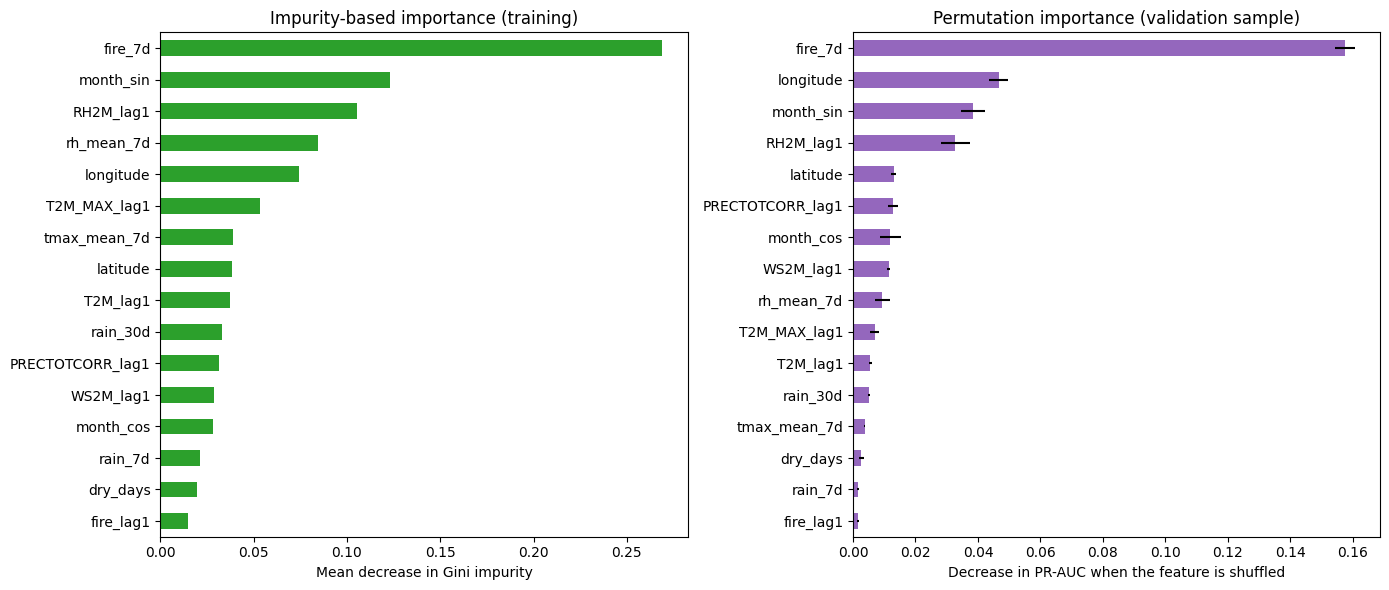

In [13]:
from sklearn.inspection import permutation_importance

mdi = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()

sample = val.sample(50000, random_state=SEED)
perm = permutation_importance(
    rf, sample[FEATURES], sample["fire"],
    scoring="average_precision", n_repeats=3, random_state=SEED,
)
perm_mean = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
perm_std = pd.Series(perm.importances_std, index=FEATURES)[perm_mean.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
mdi.plot.barh(ax=axes[0], color="tab:green")
axes[0].set_title("Impurity-based importance (training)")
axes[0].set_xlabel("Mean decrease in Gini impurity")

perm_mean.plot.barh(ax=axes[1], color="tab:purple", xerr=perm_std)
axes[1].set_title("Permutation importance (validation sample)")
axes[1].set_xlabel("Decrease in PR-AUC when the feature is shuffled")

plt.tight_layout()
plt.show()

**Interpretation.** Both measures agree that `fire_7d` (number of fire days in the municipality during
the previous week) is by far the most important feature: shuffling it reduces PR-AUC by ≈0.16, almost
half of the model's PR-AUC. In contrast, `fire_lag1` (fire on the previous day) is the least important,
consistent with the weak persistence baseline. This suggests that fires do not persist at the same place,
but municipalities go through active burning periods lasting several days (e.g., land-clearing cycles;
a hypothesis). Location and seasonality (`longitude`, `month_sin`, `latitude`, `month_cos`) come next,
consistent with the strong climatology baseline. Among weather variables, previous-day relative humidity
is the most informative. Accumulated rainfall and consecutive dry days have low importance, contrary to
our expectation from the EDA; this is likely due to redundancy with humidity, season and fire history
(permutation importance underestimates correlated features), not necessarily lack of information.
The impurity-based ranking overestimates some correlated continuous features (e.g., `rh_mean_7d`), so
permutation importance, computed on unseen data, is considered more reliable.
Since climatology does not use fire history, the gain of the Random Forest may come mainly from
`fire_7d` rather than from weather. This is tested in the ablation study below.

## 10. Ablation Study
To identify where the predictive power comes from, the same Random Forest (same hyperparameters) is
trained with different feature groups:
- **Context:** month (cyclical), latitude, longitude — *where* and *when*
- **Weather:** previous-day weather and accumulated/averaged weather variables
- **Fire history:** `fire_lag1`, `fire_7d`

Key comparisons: *Context + Weather* vs *Context only* measures the added value of weather beyond
seasonality and location (the main research question); *All features* vs *Context + Fire history*
measures the added value of weather when fire history is already known.

In [14]:
WEATHER = [f"{c}_lag1" for c in weather_cols] + ["rain_7d", "rain_30d", "rh_mean_7d", "tmax_mean_7d", "dry_days"]
FIRE_HIST = ["fire_lag1", "fire_7d"]
CONTEXT = ["month_sin", "month_cos", "latitude", "longitude"]

configs = {
    "Context only": CONTEXT,
    "Weather only": WEATHER,
    "Context + Weather": CONTEXT + WEATHER,
    "Context + Fire history": CONTEXT + FIRE_HIST,
    "All features": CONTEXT + WEATHER + FIRE_HIST,
}

def make_rf():
    return RandomForestClassifier(
        n_estimators=200, min_samples_leaf=50, max_features="sqrt", max_samples=0.3,
        class_weight="balanced_subsample", n_jobs=-1, random_state=SEED,
    )

ablation = []
for name, feats in configs.items():
    if name == "All features":
        scores = s_rf_val  # already trained in Section 8
    else:
        start = time.time()
        model = make_rf().fit(train[feats], y_train)
        scores = model.predict_proba(val[feats])[:, 1]
        print(f"{name}: trained in {time.time() - start:.0f} s")
    row = evaluate(name, y_val, scores, best_threshold(y_val, scores))
    row["n_features"] = len(feats)
    ablation.append(row)

ablation_df = pd.DataFrame(ablation).round(3)
ablation_df

Context only: trained in 31 s
Weather only: trained in 105 s
Context + Weather: trained in 84 s
Context + Fire history: trained in 30 s


,model,PR-AUC,ROC-AUC,precision,recall,F1,threshold,n_features
0,Context only,0.310,0.869,0.318,0.449,0.372,0.817,4
1,Weather only,0.197,0.803,0.207,0.352,0.261,0.655,10
2,Context + Weather,0.282,0.860,0.265,0.483,0.342,0.631,14
3,Context + Fire history,0.334,0.878,0.368,0.411,0.388,0.833,6
4,All features,0.339,0.877,0.365,0.406,0.385,0.792,16


**Interpretation.** *Context only* (PR-AUC 0.310) matches the climatology baseline (0.308), showing that
the forest learns the seasonal and spatial pattern. *Weather only* (0.197) carries signal (≈4× a random
classifier) but much less than context. Surprisingly, adding weather to context *decreases* performance
(0.282 vs 0.310). Possible explanations (hypotheses): (i) weather is largely redundant with seasonality,
adding noise rather than new information; (ii) with `max_features="sqrt"`, about one third of the splits
(C(10,3)/C(14,3) ≈ 33%) cannot consider any context feature and must use noisier weather features;
(iii) weather–fire relationships learned in 2015–2022 may not transfer to the drier validation years;
(iv) the ≈50 km resolution of NASA POWER may not capture local conditions.
Fire history adds +0.024 over context (0.334), while weather adds only +0.005 once fire history is known
(0.339). Therefore, the gain over climatology comes mainly from recent fire activity, not from weather.
At the municipality-day scale and with these data, weather variables add little predictive power beyond
location, season and recent fire history. Whether the small differences are robust is examined next.

## 11. Stability Across Random Seeds
Random Forest training is stochastic (bootstrap sampling and feature subsampling). To check whether the
differences found in the ablation study are larger than this natural variability, the four main
configurations are retrained with 5 different random seeds and evaluated on the validation set (PR-AUC).

In [15]:
SEEDS = [0, 1, 2, 3, 4]
stability_configs = ["Context only", "Context + Weather", "Context + Fire history", "All features"]

if "stab_rows" not in globals():
    stab_rows = []
done = {(r["config"], r["seed"]) for r in stab_rows}

for seed in SEEDS:
    for name in stability_configs:
        if (name, seed) in done:
            continue
        feats = configs[name]
        model = make_rf()
        model.set_params(random_state=seed)
        model.fit(train[feats], y_train)
        scores = model.predict_proba(val[feats])[:, 1]
        stab_rows.append({"config": name, "seed": seed, "PR-AUC": average_precision_score(y_val, scores)})
        print(f"Seed {seed} | {name}: {stab_rows[-1]['PR-AUC']:.4f}", flush=True)

stab = pd.DataFrame(stab_rows)
summary = (stab.groupby("config")["PR-AUC"]
           .agg(["mean", "std", "min", "max"])
           .loc[stability_configs].round(4))
summary

Seed 0 | Context only: 0.3098
Seed 0 | Context + Weather: 0.2836
Seed 0 | Context + Fire history: 0.3334
Seed 0 | All features: 0.3391
Seed 1 | Context only: 0.3096
Seed 1 | Context + Weather: 0.2835
Seed 1 | Context + Fire history: 0.3337
Seed 1 | All features: 0.3393
Seed 2 | Context only: 0.3095
Seed 2 | Context + Weather: 0.2849
Seed 2 | Context + Fire history: 0.3332
Seed 2 | All features: 0.3389
Seed 3 | Context only: 0.3096
Seed 3 | Context + Weather: 0.2838
Seed 3 | Context + Fire history: 0.3333
Seed 3 | All features: 0.3397
Seed 4 | Context only: 0.3096
Seed 4 | Context + Weather: 0.2835
Seed 4 | Context + Fire history: 0.3338
Seed 4 | All features: 0.3388


,mean,std,min,max
config,,,,
Context only,0.3096,0.0001,0.3095,0.3098
Context + Weather,0.2839,0.0006,0.2835,0.2849
Context + Fire history,0.3335,0.0002,0.3332,0.3338
All features,0.3391,0.0004,0.3388,0.3397


**Interpretation.** Variability across seeds is negligible (standard deviation ≤ 0.0006), so all
differences found in the ablation study are far larger than seed-induced variation. Adding weather to
context consistently *reduces* PR-AUC (−0.026), fire history consistently increases it (+0.024), and
weather adds a small but consistent gain once fire history is known (+0.006; the worst *All features* run,
0.3388, exceeds the best *Context + Fire history* run, 0.3338). This last gain is robust but small
(≈2% relative), so it is consistent rather than practically large. Note that seeds capture model
variability only, not variability due to the evaluation period (all runs use 2023–2024); the test year
(2025) provides an independent check.

In [16]:
#(diferenças pareadas, semente a semente)

pivot = stab.pivot(index="seed", columns="config", values="PR-AUC")
pivot["Weather gain | context"] = pivot["Context + Weather"] - pivot["Context only"]
pivot["Weather gain | context + fire"] = pivot["All features"] - pivot["Context + Fire history"]
pivot["Fire-history gain | context"] = pivot["Context + Fire history"] - pivot["Context only"]
pivot.round(4)

config,All features,Context + Fire history,Context + Weather,Context only,Weather gain | context,Weather gain | context + fire,Fire-history gain | context
seed,,,,,,,
0,0.3391,0.3334,0.2836,0.3098,-0.0263,0.0056,0.0236
1,0.3393,0.3337,0.2835,0.3096,-0.0261,0.0056,0.0241
2,0.3389,0.3332,0.2849,0.3095,-0.0245,0.0056,0.0238
3,0.3397,0.3333,0.2838,0.3096,-0.0257,0.0064,0.0238
4,0.3388,0.3338,0.2835,0.3096,-0.0260,0.0049,0.0243


## 12. Final Evaluation on the Test Set (2025)
All models were trained on 2015–2022 and their decision thresholds were selected on the validation set
(2023–2024). The test set is used once, with no further tuning.

In [17]:
val_thr = pd.DataFrame(results).set_index("model")["threshold"]
ablation_thr = ablation_df.set_index("model")["threshold"]

test_results = []

# Baselines
test_results.append(evaluate("Persistence", y_test, test["fire_lag1"].values, 0.5))
s_clim_test = test.join(clim, on=["mun_key", "month"])["clim"].fillna(train["fire"].mean()).values
test_results.append(evaluate("Climatology", y_test, s_clim_test, val_thr["Climatology"]))
s_lr_test = logreg.predict_proba(X_test)[:, 1]
test_results.append(evaluate("Logistic Regression", y_test, s_lr_test, val_thr["Logistic Regression"]))

# Random Forest variants (same seed as in the ablation study)
test_scores = {}
for name in ["Context only", "Context + Weather", "Context + Fire history", "All features"]:
    if name == "All features":
        feats, m = FEATURES, rf  # model from Section 8
    else:
        feats = configs[name]
        m = make_rf().fit(train[feats], y_train)
    test_scores[name] = m.predict_proba(test[feats])[:, 1]
    test_results.append(evaluate(f"RF: {name}", y_test, test_scores[name], ablation_thr[name]))

test_df = pd.DataFrame(test_results).round(3)
test_df

,model,PR-AUC,ROC-AUC,precision,recall,F1,threshold
0,Persistence,0.082,0.580,0.203,0.203,0.203,0.500
1,Climatology,0.256,0.848,0.277,0.377,0.319,0.171
2,Logistic Regression,0.262,0.847,0.291,0.372,0.326,0.832
3,RF: Context only,0.257,0.850,0.275,0.377,0.318,0.817
4,RF: Context + Weather,0.233,0.841,0.241,0.430,0.309,0.631
5,RF: Context + Fire history,0.274,0.862,0.320,0.335,0.327,0.833
6,RF: All features,0.286,0.862,0.323,0.347,0.335,0.792


**Interpretation.** All models perform worse in 2025 than in validation, by a similar proportion
(e.g., climatology 0.308 → 0.256, Random Forest 0.339 → 0.286, ≈16–18% drops). Since even climatology,
which cannot overfit, drops by the same amount, this reflects a harder test year (distribution shift
between years) rather than overfitting of the Random Forest. The ranking of models is preserved:
the full Random Forest remains the best model (PR-AUC 0.286), with a gain over climatology similar to
validation (+0.030, ≈12% relative). The ablation conclusions also hold: weather alone on top of context
reduces performance (−0.024), fire history improves it (+0.017), and weather adds a small gain once fire
history is known (+0.012, larger than in validation). Recall at the validation-selected threshold dropped
more than precision (0.406 → 0.347), indicating that a fixed threshold becomes conservative in a year
with more fire activity. As the test set covers a single year, these results should be interpreted with caution.

## 13. Error Analysis (Test Set, 2025)
Error analysis of the full Random Forest at the validation-selected threshold: precision–recall curves,
confusion matrix, performance by month and biome, and performance on new outbreaks (no fire in the
municipality during the previous 7 days) versus ongoing fire activity.

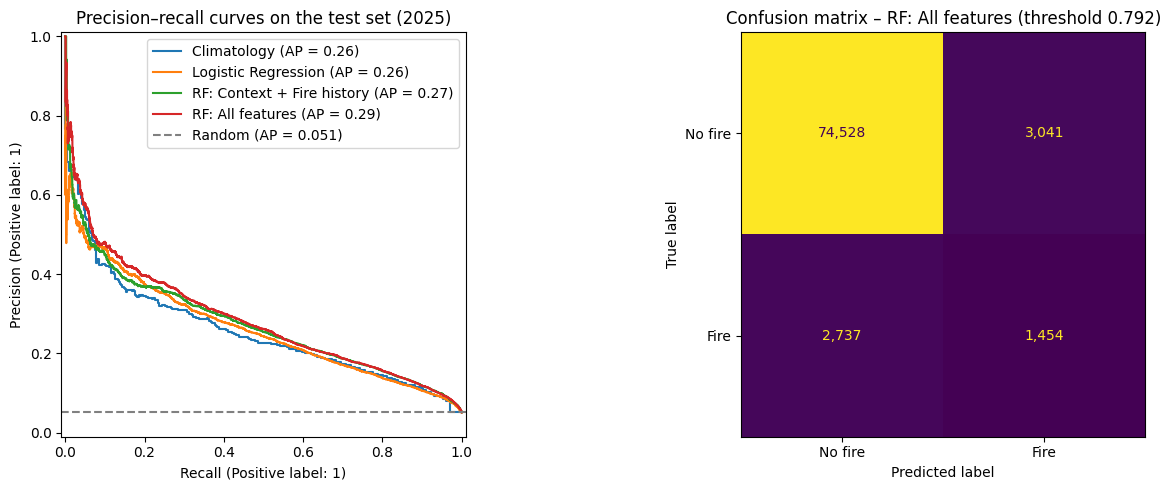

Correct alerts (TP): 1,454 | False alarms (FP): 3,041 | Missed fires (FN): 2,737 | Correct no-alert (TN): 74,528


In [18]:
from sklearn.metrics import PrecisionRecallDisplay, confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

curves = {
    "Climatology": s_clim_test,
    "Logistic Regression": s_lr_test,
    "RF: Context + Fire history": test_scores["Context + Fire history"],
    "RF: All features": test_scores["All features"],
}
for name, s in curves.items():
    PrecisionRecallDisplay.from_predictions(y_test, s, name=name, ax=axes[0])
axes[0].axhline(y_test.mean(), ls="--", color="gray", label=f"Random (AP = {y_test.mean():.3f})")
axes[0].set_title("Precision–recall curves on the test set (2025)")
axes[0].legend()

thr = ablation_thr["All features"]
pred_test = (test_scores["All features"] >= thr).astype(int)
cm = confusion_matrix(y_test, pred_test)
ConfusionMatrixDisplay(cm, display_labels=["No fire", "Fire"]).plot(
    ax=axes[1], values_format=",", colorbar=False)
axes[1].set_title(f"Confusion matrix – RF: All features (threshold {thr:.3f})")

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Correct alerts (TP): {tp:,} | False alarms (FP): {fp:,} | "
      f"Missed fires (FN): {fn:,} | Correct no-alert (TN): {tn:,}")

In [19]:
# Main biome of each municipality (most frequent biome among its fire detections)
mun_biome = fires.groupby("mun_key")["Bioma"].agg(lambda s: s.mode().iloc[0])

err = test[["mun_key", "month", "fire", "fire_7d"]].copy()
err["score"] = test_scores["All features"]
err["pred"] = pred_test
err["biome"] = err["mun_key"].map(mun_biome)

def group_metrics(df, by):
    rows = []
    for key, g in df.groupby(by):
        n_fire = g["fire"].sum()
        pr_auc = average_precision_score(g["fire"], g["score"]) if n_fire > 0 else np.nan
        rows.append({
            by: key,
            "fire_days": n_fire,
            "fire_rate": g["fire"].mean(),
            "PR-AUC": pr_auc,
            "lift": pr_auc / g["fire"].mean() if n_fire > 0 else np.nan,
            "precision": precision_score(g["fire"], g["pred"], zero_division=0),
            "recall": recall_score(g["fire"], g["pred"], zero_division=0),
        })
    return pd.DataFrame(rows).round(3)

by_month = group_metrics(err, "month")
by_biome = group_metrics(err, "biome")
display(by_month)
display(by_biome)

,month,fire_days,fire_rate,PR-AUC,lift,precision,recall
0,1,88,0.013,0.039,3.045,0.000,0.000
1,2,56,0.009,0.036,4.001,0.000,0.000
2,3,37,0.005,0.054,10.105,0.000,0.000
3,4,42,0.006,0.055,8.839,0.000,0.000
4,5,101,0.015,0.129,8.839,0.000,0.000
5,6,152,0.023,0.171,7.575,0.295,0.086
6,7,346,0.050,0.350,7.034,0.367,0.500
7,8,457,0.066,0.348,5.281,0.328,0.538
8,9,690,0.103,0.357,3.480,0.284,0.517
9,10,1109,0.160,0.329,2.061,0.333,0.462


,biome,fire_days,fire_rate,PR-AUC,lift,precision,recall
0,Caatinga,2704,0.040,0.233,5.778,0.311,0.240
1,Cerrado,1487,0.102,0.375,3.684,0.334,0.542


In [20]:
err["situation"] = np.where(err["fire_7d"] == 0,
                            "New outbreak (no fire in previous 7 days)",
                            "Ongoing activity (fire in previous 7 days)")
by_situation = group_metrics(err, "situation")
by_situation["share_of_fire_days"] = (by_situation["fire_days"] / err["fire"].sum()).round(3)
by_situation

,situation,fire_days,fire_rate,PR-AUC,lift,precision,recall,share_of_fire_days
0,New outbreak (no fire in previous 7 days),1341,0.021,0.085,4.092,0.227,0.004,0.32
1,Ongoing activity (fire in previous 7 days),2850,0.168,0.354,2.105,0.324,0.508,0.68
